# Titanic passengers

#### Goal: to predict whether a person will survive or not?

http://kaggle.com/competitions/titanic

In [1]:

# import libraries
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [2]:
# read data and get train info

from google.colab import drive
drive.mount('/content/drive')

train = pd.read_csv('/content/drive/My Drive/train.csv')
test = pd.read_csv('/content/drive/My Drive/test.csv')



Mounted at /content/drive


# Take a look on the data

In [3]:
train

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [4]:
test

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...
413,1305,3,"Spector, Mr. Woolf",male,NaN,0,0,A.5. 3236,8.0500,NaN,S
414,1306,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C105,C
415,1307,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,NaN,S
416,1308,3,"Ware, Mr. Frederick",male,NaN,0,0,359309,8.0500,NaN,S


In [8]:
train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [9]:
# show the overall survival rate
print('Overall Survival Rate:', round(train['Survived'].mean(), 3))

Overall Survival Rate: 0.384


<BarContainer object of 2 artists>

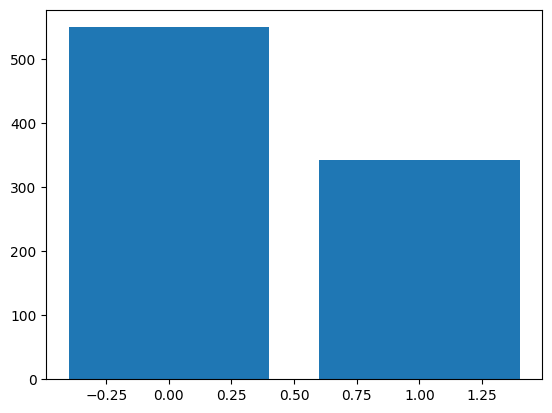

In [10]:
plt.bar(train['Survived'].value_counts().index, train['Survived'].value_counts().values)

<Axes: xlabel='Survived'>

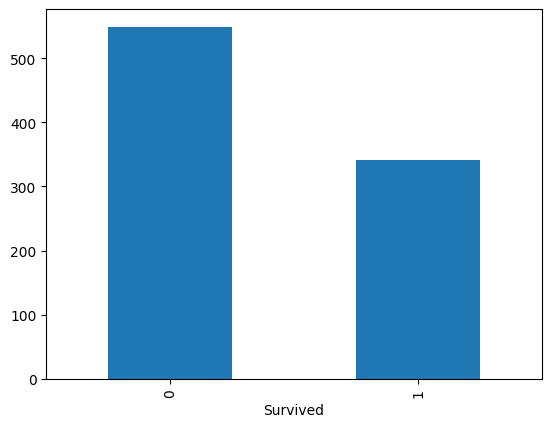

In [11]:
train['Survived'].value_counts().plot(kind = 'bar')

<BarContainer object of 3 artists>

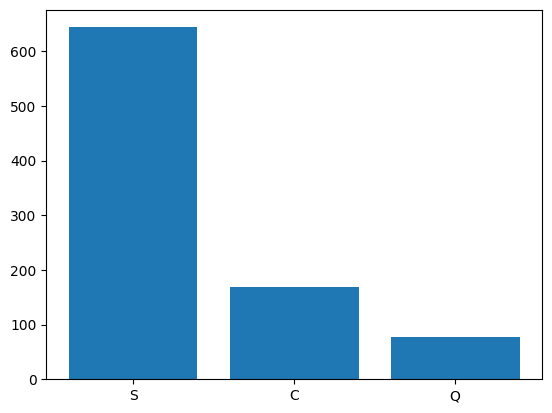

In [12]:
plt.bar(train['Embarked'].value_counts().index, train['Embarked'].value_counts().values)

# Data cleaning and feature engineering

In [13]:
train.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [14]:

# Which columns are useless?
dropping = ['PassengerId', 'Name', 'Ticket']  # ?
train.drop(dropping,axis=1, inplace=True)
test.drop(dropping,axis=1, inplace=True)

In [16]:
train.drop('Cabin',axis=1,inplace=True)
test.drop('Cabin',axis=1,inplace=True)

In [17]:
train

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S
...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S
887,1,1,female,19.0,0,0,30.0000,S
888,0,3,female,NaN,1,2,23.4500,S
889,1,1,male,26.0,0,0,30.0000,C


In [18]:
# get_dummies function
def dummies(col,train,test):
    train_dum = pd.get_dummies(train[col])
    test_dum = pd.get_dummies(test[col])
    train = pd.concat([train, train_dum], axis=1)
    test = pd.concat([test,test_dum],axis=1)
    train.drop(col,axis=1,inplace=True)
    test.drop(col,axis=1,inplace=True)
    return train, test

Pclass
3    491
1    216
2    184
Name: count, dtype: int64


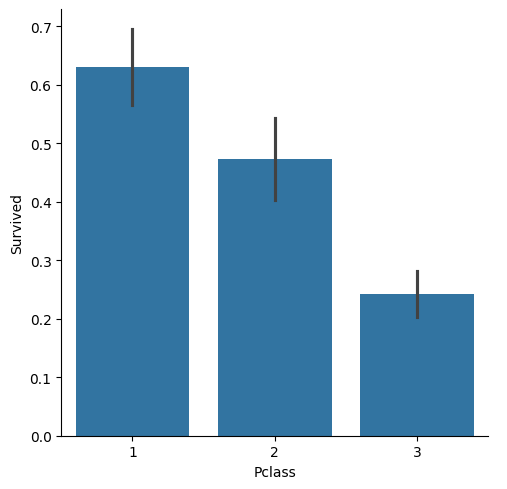

In [19]:
# pclass
# ensure no NA contained
print(train.Pclass.value_counts(dropna=False))
sns.catplot(x=train['Pclass'], y=train['Survived'], kind="bar")

# according to the graph, we found there are huge differences between
# each pclass group. So, let's keep the feature
train, test = dummies('Pclass', train, test)

In [ ]:
train

Sex
male      577
female    314
Name: count, dtype: int64


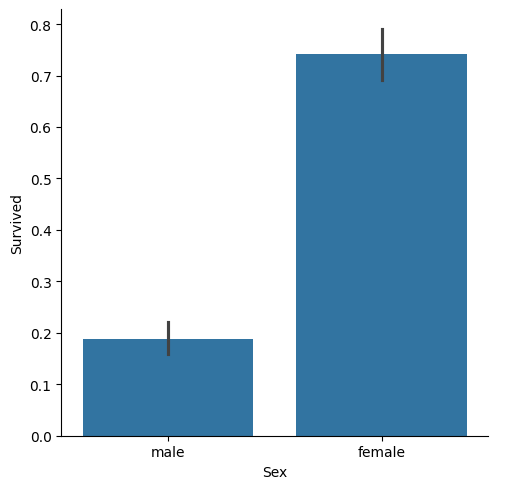

In [20]:
# sex
print(train.Sex.value_counts(dropna=False))
sns.catplot(x=train['Sex'], y=train['Survived'], kind="bar")
# female survival rate is way better than the male



In [21]:
# age
# dealing the missing data
nan_num = train['Age'].isnull().sum()
print(nan_num)

177


In [22]:
# there are 177 missing value, fill with random int
age_mean = train['Age'].mean()
age_std = train['Age'].std()
filling = np.random.randint(age_mean-age_std, age_mean+age_std, size=nan_num)
train['Age'][train['Age'].isnull()==True] = filling
nan_num = train['Age'].isnull().sum()
print(nan_num)

0


In [23]:
# dealing the missing val in test
nan_num = test['Age'].isnull().sum()
print(nan_num)

86


In [24]:
# 86 null
age_mean = test['Age'].mean()
age_std = test['Age'].std()
filling = np.random.randint(age_mean-age_std,age_mean+age_std,size=nan_num)
test['Age'][test['Age'].isnull()==True]=filling
nan_num = test['Age'].isnull().sum()
print(nan_num)

0


SibSp
0    608
1    209
2     28
4     18
3     16
8      7
5      5
Name: count, dtype: int64
Parch
0    678
1    118
2     80
5      5
3      5
4      4
6      1
Name: count, dtype: int64


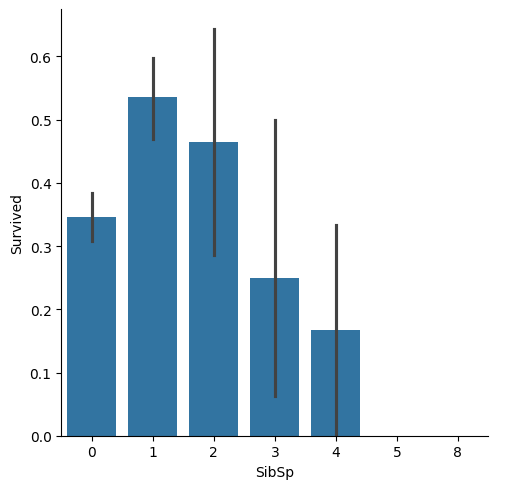

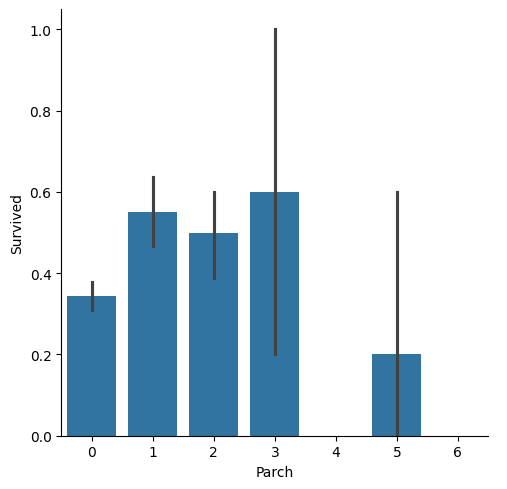

In [25]:
# family
print(train['SibSp'].value_counts(dropna=False))
print(train['Parch'].value_counts(dropna=False))
sns.catplot(x=train['SibSp'], y=train['Survived'], kind="bar")
sns.catplot(x=train['Parch'], y=train['Survived'], kind="bar")


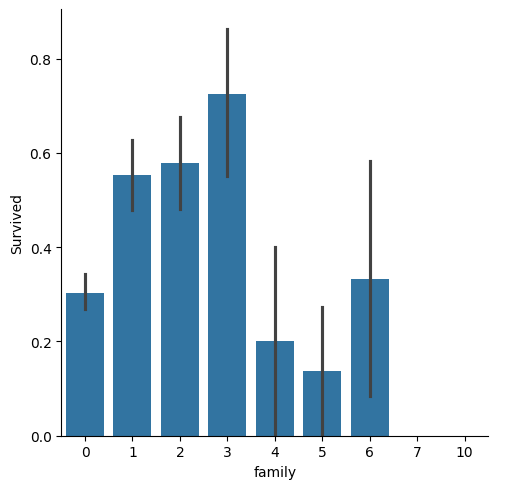

In [26]:
'''
through the plot, we can suppose that with more family members,
the survival rate drops
we can create the new col
by combining "parch" and "sibsp"
'''

train['family'] = train['SibSp'] + train['Parch']
test['family'] = test['SibSp'] + test['Parch']
sns.catplot(x=train['family'], y=train['Survived'], kind="bar")

train.drop(['SibSp','Parch'],axis=1,inplace=True)
test.drop(['SibSp','Parch'],axis=1,inplace=True)

In [27]:
train

,Survived,Sex,Age,Fare,Embarked,1,2,3,family
0,0,male,22.0,7.2500,S,False,False,True,1
1,1,female,38.0,71.2833,C,True,False,False,1
2,1,female,26.0,7.9250,S,False,False,True,0
3,1,female,35.0,53.1000,S,True,False,False,1
4,0,male,35.0,8.0500,S,False,False,True,0
...,...,...,...,...,...,...,...,...,...
886,0,male,27.0,13.0000,S,False,True,False,0
887,1,female,19.0,30.0000,S,True,False,False,0
888,0,female,31.0,23.4500,S,False,False,True,3
889,1,male,26.0,30.0000,C,True,False,False,0


In [28]:
# fare
print(train.Fare.isnull().sum())
print(test.Fare.isnull().sum())

0
1


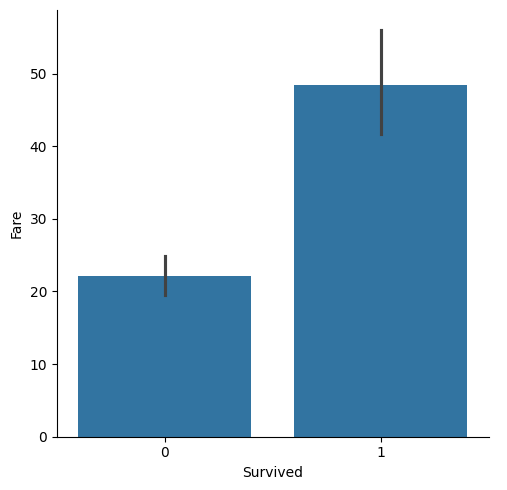

In [29]:
sns.catplot(x=train['Survived'], y=train['Fare'], kind="bar")
test['Fare'].fillna(test['Fare'].median(),inplace=True)

In [ ]:
#Cabin
# checking missing val
train.Cabin.isnull().sum()

In [ ]:
train.drop('Cabin',axis=1,inplace=True)
test.drop('Cabin',axis=1,inplace=True)

In [30]:
#Embark
print(train.Embarked.isnull().sum())
# 2 missing value
train.Embarked.value_counts()

2


,count
Embarked,
S,644
C,168
Q,77


In [31]:
# fill the majority val,'s', into missing val col
train['Embarked'].fillna('S',inplace=True)

train,test = dummies('Embarked',train,test)


In [32]:
train

,Survived,Sex,Age,Fare,1,2,3,family,C,Q,S
0,0,male,22.0,7.2500,False,False,True,1,False,False,True
1,1,female,38.0,71.2833,True,False,False,1,True,False,False
2,1,female,26.0,7.9250,False,False,True,0,False,False,True
3,1,female,35.0,53.1000,True,False,False,1,False,False,True
4,0,male,35.0,8.0500,False,False,True,0,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...
886,0,male,27.0,13.0000,False,True,False,0,False,False,True
887,1,female,19.0,30.0000,True,False,False,0,False,False,True
888,0,female,31.0,23.4500,False,False,True,3,False,False,True
889,1,male,26.0,30.0000,True,False,False,0,True,False,False


In [33]:
train['Sex'] = train['Sex'].map({'male': 0, 'female': 1})

In [34]:
train

,Survived,Sex,Age,Fare,1,2,3,family,C,Q,S
0,0,0,22.0,7.2500,False,False,True,1,False,False,True
1,1,1,38.0,71.2833,True,False,False,1,True,False,False
2,1,1,26.0,7.9250,False,False,True,0,False,False,True
3,1,1,35.0,53.1000,True,False,False,1,False,False,True
4,0,0,35.0,8.0500,False,False,True,0,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...
886,0,0,27.0,13.0000,False,True,False,0,False,False,True
887,1,1,19.0,30.0000,True,False,False,0,False,False,True
888,0,1,31.0,23.4500,False,False,True,3,False,False,True
889,1,0,26.0,30.0000,True,False,False,0,True,False,False


In [35]:
train = train * 1

In [36]:
train

,Survived,Sex,Age,Fare,1,2,3,family,C,Q,S
0,0,0,22.0,7.2500,0,0,1,1,0,0,1
1,1,1,38.0,71.2833,1,0,0,1,1,0,0
2,1,1,26.0,7.9250,0,0,1,0,0,0,1
3,1,1,35.0,53.1000,1,0,0,1,0,0,1
4,0,0,35.0,8.0500,0,0,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...
886,0,0,27.0,13.0000,0,1,0,0,0,0,1
887,1,1,19.0,30.0000,1,0,0,0,0,0,1
888,0,1,31.0,23.4500,0,0,1,3,0,0,1
889,1,0,26.0,30.0000,1,0,0,0,1,0,0


# Model and prediction

---



In [37]:
# import machine learning libraries
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split


X=train.drop('Survived',axis=1)
y=train['Survived']
#X['Sex'] = X['Sex'].map({'male': 0, 'female': 1})
X.columns = X.columns.astype(str)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2)


# check classification scores of logistic regression
logreg = LogisticRegression()
logreg.fit(X_train, y_train)
y_pred = logreg.predict(X_test)


print('Train/Test split results:')
print(logreg.__class__.__name__+" accuracy is %2.3f" % accuracy_score(y_test, y_pred))


Train/Test split results:
LogisticRegression accuracy is 0.771
